# Homework 3 --- Problem 3

## Part a

In [1]:
import pandas as pd

df0 = pd.read_csv("dset0.csv", header=None)
df0

,0,1,2,3,4,5
0,1.0,1.332,4.439,-0.487,-0.873,7.0
1,1.0,0.715,4.382,-2.142,3.567,-10.0
2,0.0,-1.545,3.921,-2.139,1.540,-2.0
3,0.0,-0.008,2.427,-0.824,0.552,7.0
4,1.0,0.621,4.275,-0.816,-0.620,-4.0
...,...,...,...,...,...,...
495,0.0,0.488,1.986,-1.197,-3.191,0.0
496,0.0,0.056,2.668,-2.302,-4.224,0.0
497,0.0,0.546,4.441,-2.558,-1.637,8.0
498,1.0,-0.683,2.610,-3.230,-0.708,-1.0


In [2]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split

# Load the dataset (first column is the target)
y = df0.iloc[:, 0]
X = df0.iloc[:, 1:]

# Split into training and test sets to analyze generalization with stratification
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

tree_counts = [1, 10, 100, 300, 1000]

train_accuracies = []
test_accuracies = []

for n in tree_counts:
    clf = GradientBoostingClassifier(n_estimators=n, random_state=42)
    clf.fit(X_train, y_train)

    train_acc = clf.score(X_train, y_train)
    test_acc = clf.score(X_test, y_test)

    train_accuracies.append(train_acc)
    test_accuracies.append(test_acc)

    print(f"Trees: {n:4d} | Train Accuracy: {train_acc:.4f} | Test Accuracy: {test_acc:.4f}")

Trees:    1 | Train Accuracy: 0.5750 | Test Accuracy: 0.5700
Trees:   10 | Train Accuracy: 0.8600 | Test Accuracy: 0.7500
Trees:  100 | Train Accuracy: 0.9975 | Test Accuracy: 0.8100
Trees:  300 | Train Accuracy: 1.0000 | Test Accuracy: 0.8400
Trees: 1000 | Train Accuracy: 1.0000 | Test Accuracy: 0.8200


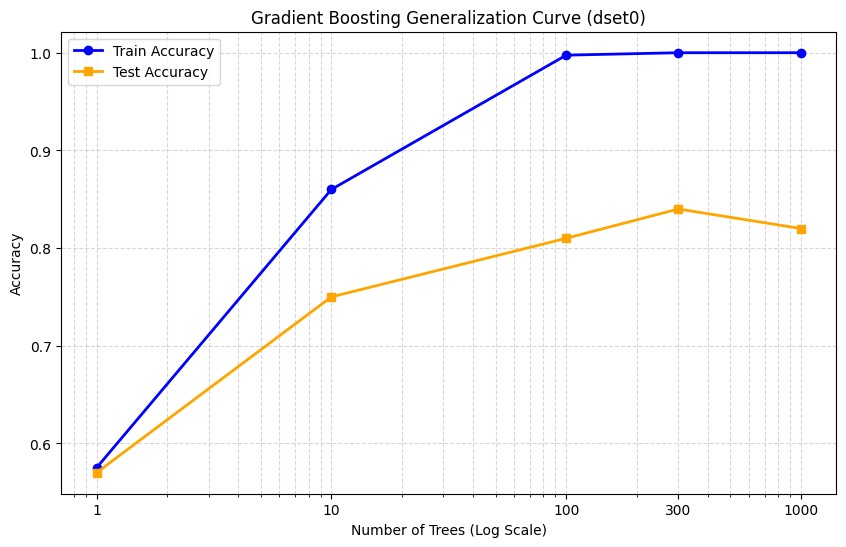

In [3]:
import matplotlib.pyplot as plt

# Using the variables already saved in the kernel memory
plt.figure(figsize=(10, 6))
plt.plot(tree_counts, train_accuracies, marker='o', label='Train Accuracy', color='blue', linewidth=2)
plt.plot(tree_counts, test_accuracies, marker='s', label='Test Accuracy', color='orange', linewidth=2)

plt.xscale('log')
plt.xlabel('Number of Trees (Log Scale)')
plt.ylabel('Accuracy')
plt.title('Gradient Boosting Generalization Curve (dset0)')
plt.xticks(tree_counts, labels=[str(t) for t in tree_counts])
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend()
plt.show()

#### Answer:

For `dset0`, increasing the number of trees up to 300 steadily improves test accuracy, indicating that the ensemble model successfully captures the signal and structures in the data. However, beyond 300 estimators, the training accuracy reaches 1.0000 while the test accuracy begins to decline, showing that the model starts to overfit to the training set noise.

## Part b

In [4]:
df1 = pd.read_csv("dset1.csv", header=None)
df1

,0,1,2,3,4,5
0,0.0,1.558,4.151,-2.741,-0.368,-4.0
1,1.0,-2.179,5.395,-2.018,-4.662,8.0
2,0.0,0.841,3.552,-1.664,3.957,-9.0
3,0.0,0.438,2.388,-0.383,-2.309,3.0
4,1.0,-0.457,2.534,-1.893,-0.634,4.0
...,...,...,...,...,...,...
495,1.0,-0.439,2.472,-1.614,-3.059,-7.0
496,0.0,0.073,2.527,-3.146,-1.365,4.0
497,0.0,0.253,3.967,-3.624,-0.831,1.0
498,1.0,0.192,2.336,-1.860,-4.202,-3.0


In [5]:
# Prepare features and target from df1
y1 = df1.iloc[:, 0]
X1 = df1.iloc[:, 1:]

# Split into training and test sets with stratification
X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size=0.2, random_state=42, stratify=y1)

tree_counts_b = [1, 10, 100, 300, 1000]
train_accuracies_b = []
test_accuracies_b = []

for n in tree_counts_b:
    clf = GradientBoostingClassifier(n_estimators=n, random_state=42)
    clf.fit(X1_train, y1_train)

    train_acc = clf.score(X1_train, y1_train)
    test_acc = clf.score(X1_test, y1_test)

    train_accuracies_b.append(train_acc)
    test_accuracies_b.append(test_acc)

    print(f"Trees: {n:4d} | Train Accuracy: {train_acc:.4f} | Test Accuracy: {test_acc:.4f}")

Trees:    1 | Train Accuracy: 0.7050 | Test Accuracy: 0.6900
Trees:   10 | Train Accuracy: 0.8825 | Test Accuracy: 0.7600
Trees:  100 | Train Accuracy: 0.9925 | Test Accuracy: 0.8100
Trees:  300 | Train Accuracy: 1.0000 | Test Accuracy: 0.7900
Trees: 1000 | Train Accuracy: 1.0000 | Test Accuracy: 0.7900


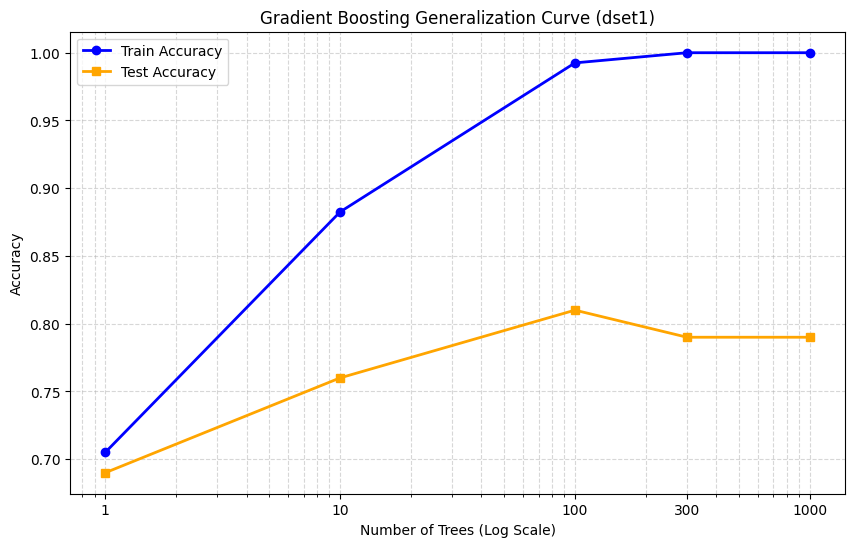

In [6]:
# Plot the results for Part b
plt.figure(figsize=(10, 6))
plt.plot(tree_counts_b, train_accuracies_b, marker='o', label='Train Accuracy', color='blue', linewidth=2)
plt.plot(tree_counts_b, test_accuracies_b, marker='s', label='Test Accuracy', color='orange', linewidth=2)

plt.xscale('log')
plt.xlabel('Number of Trees (Log Scale)')
plt.ylabel('Accuracy')
plt.title('Gradient Boosting Generalization Curve (dset1)')
plt.xticks(tree_counts_b, labels=[str(t) for t in tree_counts_b])
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend()
plt.show()

#### Answer:

For `dset1`, a single tree already yields a high baseline test accuracy of 69.00%, showing strong initial predictive signal, with the peak test performance reached at 100 trees (81.00%). Beyond 100 trees, the test accuracy drops and plateaus at 79.00% while training accuracy reaches 1.0000, indicating that adding more estimators leads to overfitting.

## Part c

#### Answer:

The primary difference is that `dset1` exhibits a significantly higher baseline test accuracy of 69.00% with only a single tree compared to `dset0`'s 57.00% and reaches its peak performance at 100 trees, which indicates that `dset1` has stronger individual predictive features or a cleaner decision boundary. Consequently, `dset0` contains higher feature complexity or noise, requiring an ensemble of up to 300 estimators to capture the signal and maximize test performance before overfitting.